# Porównanie detektorów — Binoculars, Fast-DetectGPT i Pangram EditLens na artykułach z `data/processed`

**Pytanie badawcze:** ile polskojęzycznych serwisów „newsowych” publikuje masowo treści generowane przez AI?

**Co tu jest.** Wyniki dwóch par modeli Bielik (`bielik-1.5b` i `bielik-4.5b` w 8 bitach), policzone przez `python -m news_detector.detect score`, oraz raporty z `python -m news_detector.detect report`.
Do tego Pangram EditLens (klasyfikator Llama-3.2-3B, uczony na angielskim), liczony tą samą komendą do `data/detect/pangram.csv` i pokazywany w osobnym panelu, bo nie zależy od pary Bielika. Jeśli brakuje `pangram.csv` lub `smigiel-pangram.csv`, notebook pomija Pangram.
Notebook niczego nie liczy modelami, tylko czyta pliki z `data/detect/` i je porównuje.

**Jak czytać wyniki (najważniejsze zasady):**

1. Detektor zwraca **liczbę, nie prawdopodobieństwo**. Decyzję „oznaczony / nie” podejmuje próg.
2. Próg ustawiamy na tekstach z lat **2020–2022** (sprzed ChatGPT, zakładamy: ludzkie) tak, żeby oznaczać tylko 5% (albo 1%) z nich. To jest przyjęty z góry **odsetek fałszywych alarmów (FPR)**.
3. **Wynik to różnica** między odsetkiem oznaczonych w 2023–2025 a tym w 2020–2022, a nie pojedyncze „oznaczone” artykuły.
4. Czułość detektora (ile prawdziwego AI wykrywa) mierzymy **tylko na zbiorze Śmigiel** (PolEval 2025), bo w naszych danych nie ma tekstów o znanym pochodzeniu.

**Spis:**
1. Dane i pokrycie
2. Czy implementacja działa? (Śmigiel)
3. Gdzie leżą nasze artykuły na tle znanych tekstów
4. Kalibracja i test placebo
5. Wynik główny: 2023–2025 kontra 2020–2022
6. Domeny
7. Zgodność detektorów i modeli
8. Moc testu i korekta na czułość
9. Kandydaci do ręcznego przeglądu
10. Wnioski i następne kroki


## 0. Konfiguracja

In [ ]:
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from news_detector.detect.data import text_key
from news_detector.detect.report import (
    DIRECTIONS,
    benjamini_hochberg,
    fisher_greater,
    threshold_at_fpr,
    wilson_interval,
)
from news_detector.detect.smigiel import evaluate as smigiel_evaluate
from news_detector.pipeline.build import GOLD_YEARS

DETECT_DIR = Path("../../data/detect")
PROCESSED_DIR = Path("../../data/processed")
SMIGIEL_SAMPLE = Path("../../data/external/smigiel/sample.csv")

PRESETS = {"bielik-1.5b": "Bielik 1.5B", "bielik-4.5b": "Bielik 4.5B (8-bit)"}
SMALL, LARGE = list(PRESETS)
DETECTORS = {
    "binoculars": "Binoculars",
    "fastdetectgpt_observer": "Fast-DetectGPT (model bazowy)",
    "fastdetectgpt_performer": "Fast-DetectGPT (model instrukcyjny)",
    "logppl_observer": "zwykła perplexity (punkt odniesienia)",
}
PANGRAM = "pangram_score"
PANGRAM_NAME = "Pangram EditLens"
assert set(DETECTORS) | {PANGRAM} == set(DIRECTIONS)
DET_NAMES = {**DETECTORS, PANGRAM: PANGRAM_NAME}
FPRS = (0.01, 0.05)
MAIN_FPR = 0.05

# Pangram nie zależy od pary modeli Bielika, więc jest osobnym panelem obok presetów
HAS_PANGRAM = all(
    (DETECT_DIR / name).exists() for name in ("pangram.csv", "smigiel-pangram.csv")
)
if not HAS_PANGRAM:
    print("Brak pangram.csv lub smigiel-pangram.csv w data/detect: pomijam Pangram")
PANELS = {**PRESETS, **({"pangram": PANGRAM_NAME} if HAS_PANGRAM else {})}
PANEL_DETECTORS = {p: DETECTORS if p in PRESETS else {PANGRAM: PANGRAM_NAME} for p in PANELS}

# Kolejne sloty kategorialnej palety bazowej; kolor = detektor we wszystkich wykresach
DET_COLOR = dict(
    zip(DETECTORS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"], strict=True)
)
DET_COLOR[PANGRAM] = "#8e5bd9"
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8985"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (10, 4),
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 11,
        "legend.frameon": False,
    }
)


def pct(x: float) -> str:
    return f"{100 * x:.1f}%"


## 1. Dane i pokrycie

Artykuły bierzemy z `train.csv`, `dev.csv` i `test.csv` (razem wszystkie), a wyniki łączymy z nimi po skrócie SHA-1 tekstu.
Podział na zbiory służy tu tylko do jednego: **próg ustawiamy na `train` + `dev`, a `test` (tylko lata 2020–2022) zostaje do uczciwego sprawdzenia fałszywych alarmów**.
Do samego liczenia wyników detektorów podział nie był potrzebny.

In [ ]:
frames = [
    pd.read_csv(
        PROCESSED_DIR / f"{split}.csv",
        usecols=["article_id", "domain", "stratum", "url", "pub_year", "title", "text"],
    ).assign(split=split)
    for split in ("train", "dev", "test")
]
articles = pd.concat(frames, ignore_index=True)
articles = articles[articles["text"].fillna("").str.strip() != ""].copy()
articles["text_key"] = articles["text"].map(text_key)
articles["human"] = articles["pub_year"].isin(GOLD_YEARS)
articles = articles.drop(columns="text").reset_index(drop=True)

scores = {p: pd.read_csv(DETECT_DIR / f"{p}.csv") for p in PRESETS}
data = {p: articles.merge(scores[p], on="text_key", how="inner") for p in PRESETS}
if HAS_PANGRAM:
    scores["pangram"] = pd.read_csv(DETECT_DIR / "pangram.csv")
    data["pangram"] = articles.merge(scores["pangram"], on="text_key", how="inner")

coverage = pd.DataFrame(
    {
        PRESETS[p]: {
            "artykuły w danych": len(articles),
            "artykuły z wynikiem": len(data[p]),
            "unikalne teksty z wynikiem": len(scores[p]),
            "teksty ucięte do limitu tokenów": pct(
                (scores[p]["n_tokens"] >= 512).mean()
            ),
        }
        for p in PRESETS
    }
)
display(coverage)
if HAS_PANGRAM:
    print(
        f"{PANGRAM_NAME}: {len(data['pangram'])} z {len(articles)} artykułów ma wynik "
        f"({len(scores['pangram'])} unikalnych tekstów, limit 1024 tokenów)"
    )
display(pd.crosstab(articles["pub_year"], articles["split"], margins=True))


,Bielik 1.5B,Bielik 4.5B (8-bit)
artykuły w danych,5026,5026
artykuły z wynikiem,5026,5026
unikalne teksty z wynikiem,5019,5019
teksty ucięte do limitu tokenów,64.1%,64.1%


split,dev,test,train,All
pub_year,,,,
2020,92,95,738,925
2021,97,101,795,993
2022,96,92,741,929
2023,93,87,728,908
2024,70,69,560,699
2025,55,58,459,572
All,503,502,4021,5026


Uwagi o pokryciu:

- Wszystkie artykuły mają wynik, a liczba unikalnych tekstów jest nieco mniejsza niż artykułów, bo kilka artykułów jest zduplikowanych (ten sam tekst pod różnymi adresami).
- Detektor widzi tylko **pierwsze 512 tokenów** artykułu. Większość tekstów jest dłuższa, więc końcówki nie są oceniane.

In [ ]:
# Zgodność obu zestawów: te same artykuły w tej samej kolejności (potrzebne w kolejnych sekcjach)
assert (
    data[SMALL]["article_id"].to_numpy() == data[LARGE]["article_id"].to_numpy()
).all()


def machine_score(df: pd.DataFrame, det: str) -> pd.Series:
    """Wynik zorientowany tak, że WYŻSZY = bardziej podobny do AI (dla każdego detektora)."""
    return DIRECTIONS[det] * df[det]


def calibrate(df: pd.DataFrame, det: str, fpr: float) -> float:
    """Próg na tekstach z lat 2020-2022 ze zbiorów train i dev."""
    mask = df["human"] & df["split"].isin(["train", "dev"])
    return threshold_at_fpr(machine_score(df, det)[mask], fpr)


flags: dict[tuple[str, str, float], pd.Series] = {}
for p in PANELS:
    for det in PANEL_DETECTORS[p]:
        for fpr in FPRS:
            flags[(p, det, fpr)] = machine_score(data[p], det) > calibrate(
                data[p], det, fpr
            )

# Kontrola: progi policzone tu muszą zgadzać się z raportem z linii poleceń
for p in PRESETS:
    cal = pd.read_csv(DETECT_DIR / "reports" / p / "calibration.csv")
    for row in cal.itertuples():
        if row.detector == PANGRAM and not HAS_PANGRAM:
            continue
        frame = data["pangram"] if row.detector == PANGRAM else data[p]
        mine = DIRECTIONS[row.detector] * calibrate(frame, row.detector, row.target_fpr)
        assert np.isclose(mine, row.threshold, rtol=1e-4), (
            p,
            row.detector,
            mine,
            row.threshold,
        )
print("Progi zgodne z data/detect/reports/*/calibration.csv")


Progi zgodne z data/detect/reports/*/calibration.csv


## 2. Czy implementacja działa? Śmigiel (znane teksty ludzkie i AI)

Próbka 1000 tekstów ze zbioru PolEval 2025 „Śmigiel” (500 ludzkich, 500 z LLM-ów: Bielik, PLLuM, Llama, Mistral, Gemma).
To jedyne miejsce, w którym znamy prawdę, więc **tu mierzymy czułość detektorów**.

- `auc`: prawdopodobieństwo, że losowy tekst AI dostanie wynik bardziej „AI” niż losowy ludzki (0,5 = rzut monetą, 1 = idealnie).
- `accuracy_median`: trafność przy progu równym medianie, tak jak w zwycięskim zgłoszeniu PolEval (około 0,80 dla Binoculars na parze Bielik 4.5B).
- `recall_at_fpr_0.05`: jaki odsetek tekstów AI wykrywamy, gdy dopuszczamy 5% fałszywych alarmów.

In [ ]:
smigiel_eval = {p: smigiel_evaluate(DETECT_DIR / f"smigiel-{p}.csv") for p in PANELS}
smigiel_table = pd.concat(
    [t.assign(model=PANELS[p]) for p, t in smigiel_eval.items()], ignore_index=True
)
smigiel_table["detector"] = smigiel_table["detector"].map(DET_NAMES)
display(smigiel_table.set_index(["model", "detector"]).drop(columns="n").round(3))

# Czułość (TPR) przy zadanym FPR, do korekty w sekcji 8
tpr_smigiel = {
    (p, det, fpr): float(
        smigiel_eval[p].set_index("detector").loc[det, f"recall_at_fpr_{fpr:g}"]
    )
    for p in PANELS
    for det in PANEL_DETECTORS[p]
    for fpr in FPRS
}

sample = pd.read_csv(SMIGIEL_SAMPLE)
sample["text_key"] = sample["text"].map(text_key)
sample = sample.drop(columns="text")
smigiel = {
    p: sample.merge(pd.read_csv(DETECT_DIR / f"smigiel-{p}.csv"), on="text_key")
    for p in PANELS
}


auc  accuracy_median  recall_at_fpr_0.01  recall_at_fpr_0.05
model               detector                                                                                             
Bielik 1.5B         Binoculars                             0.833            0.766               0.350               0.522
                    Fast-DetectGPT (model bazowy)          0.789            0.706               0.272               0.456
                    Fast-DetectGPT (model instrukcyjny)    0.798            0.710               0.204               0.470
                    zwykła perplexity (punkt odniesienia)  0.710            0.652               0.132               0.248
Bielik 4.5B (8-bit) Binoculars                             0.850            0.788               0.268               0.554
                    Fast-DetectGPT (model bazowy)          0.797            0.708               0.260               0.448
                    Fast-DetectGPT (model instrukcyjny)    0.782            0.718               0.208               0.414
                    zwykła perplexity (punkt odniesienia)  0.684            0.634               0.120               0.206

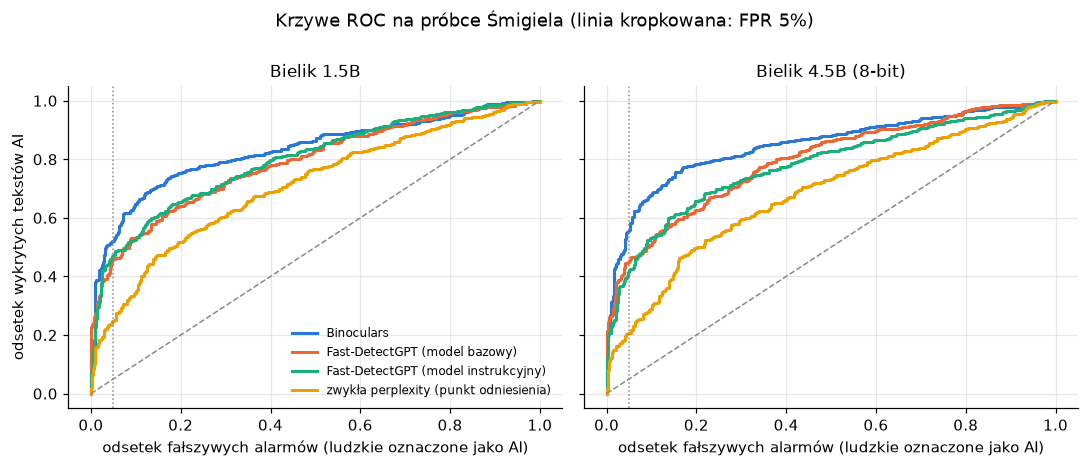

In [ ]:
def roc_curve(machine: pd.Series, labels: pd.Series) -> tuple[np.ndarray, np.ndarray]:
    order = np.argsort(-machine.to_numpy(), kind="stable")
    y = labels.to_numpy().astype(int)[order]
    return (
        np.r_[0, np.cumsum(1 - y) / (1 - y).sum()],
        np.r_[0, np.cumsum(y) / y.sum()],
    )


fig, axes = plt.subplots(1, len(PANELS), figsize=(5 * len(PANELS), 4.2), sharey=True)
for ax, p in zip(axes, PANELS, strict=True):
    for det, name in PANEL_DETECTORS[p].items():
        fpr_, tpr_ = roc_curve(machine_score(smigiel[p], det), smigiel[p]["label"])
        ax.plot(fpr_, tpr_, color=DET_COLOR[det], lw=2, label=name)
    ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1)
    ax.axvline(MAIN_FPR, color=GRAY, ls=":", lw=1)
    ax.set_title(PANELS[p])
    ax.set_xlabel("odsetek fałszywych alarmów (ludzkie oznaczone jako AI)")
axes[0].set_ylabel("odsetek wykrytych tekstów AI")
axes[0].legend(loc="lower right", fontsize=8)
fig.suptitle("Krzywe ROC na próbce Śmigiela (linia kropkowana: FPR 5%)", y=1.0)
fig.tight_layout()
plt.show()


Jak to czytać: im bardziej krzywa wypycha się w lewy górny róg, tym lepiej.
Interesuje nas lewa część wykresu (niskie FPR), bo tam pracujemy: przy FPR 5% i 1% **większość tekstów AI i tak nie zostanie wykryta** (patrz `recall_at_fpr`).
To wprost ogranicza, jak małe zjawisko jesteśmy w stanie zobaczyć w naszych danych (sekcja 8).

## 3. Gdzie leżą nasze artykuły na tle znanych tekstów

Rozkład wyniku Binoculars (niższy = bardziej AI).
Linie ciągłe to **nasze artykuły**, kropkowane to **Śmigiel**.
Jeśli artykuły z lat 2023–2025 zawierają dużo AI, ich rozkład powinien wyraźnie przesunąć się w stronę rozkładu AI ze Śmigiela (pomarańczowa kropkowana).

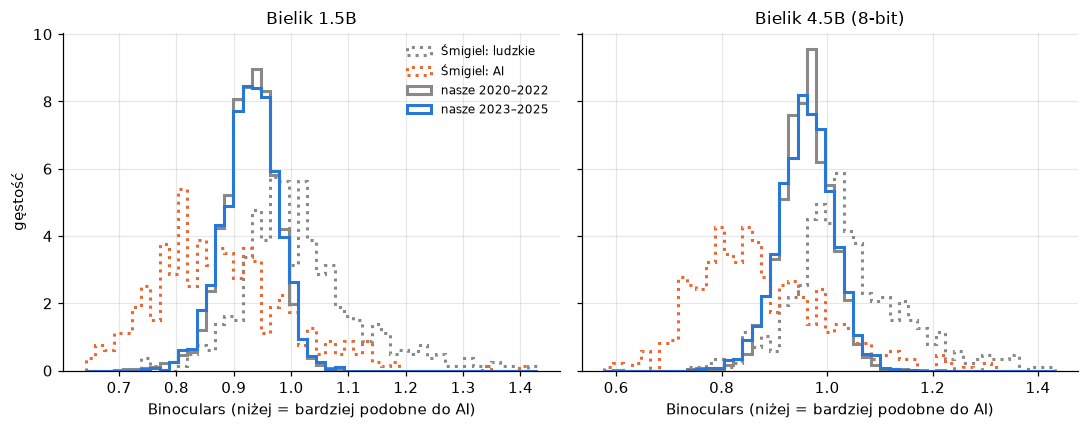

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, p in zip(axes, PRESETS, strict=True):
    series = {
        "Śmigiel: ludzkie": (
            smigiel[p].loc[smigiel[p]["label"] == 0, "binoculars"],
            GRAY,
            ":",
        ),
        "Śmigiel: AI": (
            smigiel[p].loc[smigiel[p]["label"] == 1, "binoculars"],
            ORANGE,
            ":",
        ),
        "nasze 2020–2022": (data[p].loc[data[p]["human"], "binoculars"], GRAY, "-"),
        "nasze 2023–2025": (data[p].loc[~data[p]["human"], "binoculars"], BLUE, "-"),
    }
    lo = min(s.quantile(0.005) for s, _, _ in series.values())
    hi = max(s.quantile(0.995) for s, _, _ in series.values())
    bins = np.linspace(lo, hi, 50)
    for name, (values, color, style) in series.items():
        ax.hist(
            values,
            bins=bins,
            density=True,
            histtype="step",
            lw=2,
            color=color,
            ls=style,
            label=name,
        )
    ax.set_title(PRESETS[p])
    ax.set_xlabel("Binoculars (niżej = bardziej podobne do AI)")
axes[0].set_ylabel("gęstość")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 4. Kalibracja i test placebo

**Fałszywe alarmy na zbiorze `test` (lata 2020–2022, nieużywane do ustawienia progu).**
Jeśli wynik jest blisko docelowego FPR, próg się stabilnie przenosi na nowe teksty.

In [ ]:
held = pd.concat(
    [
        pd.read_csv(DETECT_DIR / "reports" / p / "calibration.csv").assign(
            model=PRESETS[p]
        )
        for p in PRESETS
    ]
)
# Pangram nie zależy od presetu: raport każdego presetu ma te same wiersze
held.loc[held["detector"] == PANGRAM, "model"] = PANGRAM_NAME
held = held.drop_duplicates(["model", "detector", "target_fpr"])
held["detector"] = held["detector"].map(DET_NAMES)
held["fpr_heldout (95% CI)"] = held.apply(
    lambda r: (
        f"{pct(r.fpr_heldout)} [{pct(r.fpr_heldout_ci_low)}; {pct(r.fpr_heldout_ci_high)}]"
    ),
    axis=1,
)
display(
    held.pivot_table(
        index=["model", "detector"],
        columns="target_fpr",
        values="fpr_heldout (95% CI)",
        aggfunc="first",
    )
)


target_fpr                                                              0.01                0.05
model               detector                                                                    
Bielik 1.5B         Binoculars                             0.7% [0.2%; 2.5%]   4.9% [2.9%; 8.0%]
                    Fast-DetectGPT (model bazowy)          0.0% [0.0%; 1.3%]  6.9% [4.5%; 10.5%]
                    Fast-DetectGPT (model instrukcyjny)    2.1% [1.0%; 4.5%]  6.6% [4.3%; 10.1%]
                    zwykła perplexity (punkt odniesienia)  1.7% [0.7%; 4.0%]   5.6% [3.4%; 8.8%]
Bielik 4.5B (8-bit) Binoculars                             0.0% [0.0%; 1.3%]   3.8% [2.1%; 6.7%]
                    Fast-DetectGPT (model bazowy)          0.0% [0.0%; 1.3%]   5.2% [3.2%; 8.4%]
                    Fast-DetectGPT (model instrukcyjny)    0.3% [0.1%; 1.9%]   5.9% [3.7%; 9.2%]
                    zwykła perplexity (punkt odniesienia)  1.7% [0.7%; 4.0%]   5.9% [3.7%; 9.2%]

**Test placebo: odsetek oznaczonych w każdym roku (próg przy FPR 5%).**
W latach 2020–2022 powinien leżeć na linii przerywanej (5%) z definicji. Jeśli te lata się rozjeżdżają, to detektor reaguje na coś innego niż AI.
Wynik właściwy to lata 2023–2025 (zacieniowane): AI w treściach podniosłoby punkty **ponad** linię.
Słupki to 95% przedziały ufności (Wilson).

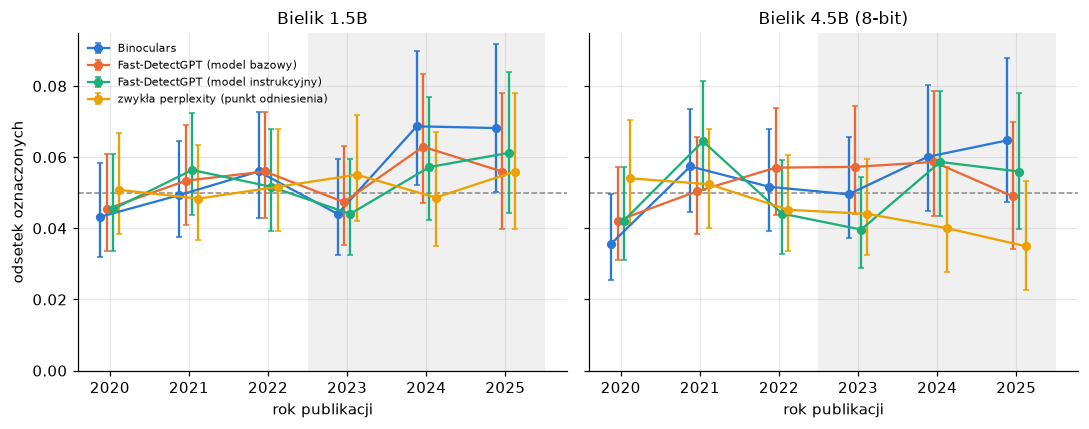

In [ ]:
def rate_by_year(p: str, det: str, fpr: float) -> pd.DataFrame:
    df, f = data[p], flags[(p, det, fpr)]
    rows = []
    for year, idx in df.groupby("pub_year").groups.items():
        k, n = int(f[idx].sum()), len(idx)
        lo, hi = wilson_interval(k, n)
        rows.append(
            {"pub_year": year, "n": n, "flagged": k, "rate": k / n, "lo": lo, "hi": hi}
        )
    return pd.DataFrame(rows)


fig, axes = plt.subplots(1, len(PANELS), figsize=(5 * len(PANELS), 4), sharey=True)
for ax, p in zip(axes, PANELS, strict=True):
    ax.axvspan(2022.5, 2025.5, color=GRAY, alpha=0.12, lw=0)
    ax.axhline(MAIN_FPR, color=GRAY, ls="--", lw=1)
    dets = PANEL_DETECTORS[p]
    for i, (det, name) in enumerate(dets.items()):
        t = rate_by_year(p, det, MAIN_FPR)
        x = t["pub_year"] + (i - (len(dets) - 1) / 2) * 0.08
        ax.errorbar(
            x,
            t["rate"],
            yerr=[t["rate"] - t["lo"], t["hi"] - t["rate"]],
            color=DET_COLOR[det],
            marker="o",
            ms=5,
            lw=1.5,
            capsize=2,
            label=name,
        )
    ax.set_title(PANELS[p])
    ax.set_xlabel("rok publikacji")
    ax.set_ylim(0, None)
axes[0].set_ylabel("odsetek oznaczonych")
axes[0].legend(fontsize=7, loc="upper left")
fig.tight_layout()
plt.show()


## 5. Wynik główny: 2023–2025 kontra 2020–2022

Dla każdego detektora: odsetek oznaczonych w latach 2020–2022 (poziom bazowy, powinien być ≈ FPR) i w latach 2023–2025, ich różnica oraz jednostronny test Fishera (czy odsetek w 2023–2025 jest **większy**).

In [ ]:
@lru_cache(maxsize=None)
def fisher(k1: int, n1: int, k0: int, n0: int) -> float:
    return fisher_greater(k1, n1, k0, n0)


def compare_periods(
    p: str, det: str, fpr: float, subset: pd.Series | None = None
) -> dict:
    df, f = data[p], flags[(p, det, fpr)]
    keep = pd.Series(True, index=df.index) if subset is None else subset
    before, after = f[keep & df["human"]], f[keep & ~df["human"]]
    n0, k0, n1, k1 = len(before), int(before.sum()), len(after), int(after.sum())
    return {
        "n 2020–22": n0,
        "oznaczone 2020–22": k0,
        "odsetek 2020–22": k0 / n0,
        "n 2023–25": n1,
        "oznaczone 2023–25": k1,
        "odsetek 2023–25": k1 / n1,
        "różnica (pp)": 100 * (k1 / n1 - k0 / n0),
        "p (Fisher)": fisher(k1, n1, k0, n0),
    }


rows = []
for fpr in FPRS:
    for p in PANELS:
        for det, name in PANEL_DETECTORS[p].items():
            rows.append(
                {
                    "FPR": f"{fpr:.0%}",
                    "model": PANELS[p],
                    "detektor": name,
                    **compare_periods(p, det, fpr),
                }
            )
overall = pd.DataFrame(rows)
fmt = {
    "odsetek 2020–22": pct,
    "odsetek 2023–25": pct,
    "różnica (pp)": "{:+.1f}".format,
    "p (Fisher)": "{:.3f}".format,
}
display(overall.set_index(["FPR", "model", "detektor"]).style.format(fmt))


**Podział na strata** (S1 = najpopularniejsze serwisy z rankingu, S2 = pozostałe z rankingu, S3 = dodane ręcznie), Binoculars przy FPR 5%.

In [10]:
rows = []
for p in PRESETS:
    for stratum in sorted(articles["stratum"].unique()):
        subset = data[p]["stratum"] == stratum
        rows.append(
            {
                "model": PRESETS[p],
                "stratum": stratum,
                **compare_periods(p, "binoculars", MAIN_FPR, subset),
            }
        )
by_stratum = pd.DataFrame(rows).set_index(["model", "stratum"])
display(by_stratum.style.format(fmt))

## 6. Domeny

Dla każdej z 44 domen: odsetek oznaczonych w 2020–2022 i 2023–2025, test Fishera i poprawka na wielokrotne testowanie (q-value, Benjamini–Hochberg).
**Przy 44 testach na poziomie 5% około 2 domen wyjdzie „istotnych” z samego przypadku**, dlatego patrzymy na q-value i na to, czy te same domeny wychodzą w obu modelach.

In [ ]:
def domain_table(p: str, det: str, fpr: float) -> pd.DataFrame:
    df, f = data[p], flags[(p, det, fpr)]
    rows = []
    for domain, group in df.groupby("domain"):
        before, after = f[group.index[group["human"]]], f[group.index[~group["human"]]]
        n0, k0, n1, k1 = len(before), int(before.sum()), len(after), int(after.sum())
        rows.append(
            {
                "domain": domain,
                "stratum": group["stratum"].iloc[0],
                "n_2020_22": n0,
                "rate_2020_22": k0 / n0 if n0 else np.nan,
                "n_2023_25": n1,
                "flagged_2023_25": k1,
                "rate_2023_25": k1 / n1 if n1 else np.nan,
                "p_value": fisher(k1, n1, k0, n0) if n0 and n1 else np.nan,
            }
        )
    table = pd.DataFrame(rows).set_index("domain")
    table["excess"] = table["rate_2023_25"] - table["rate_2020_22"]
    tested = table["p_value"].notna()
    table.loc[tested, "q_value"] = benjamini_hochberg(table.loc[tested, "p_value"])
    return table


domains = {
    (p, det): domain_table(p, det, MAIN_FPR)
    for p in PANELS
    for det in PANEL_DETECTORS[p]
}

summary = pd.DataFrame(
    {
        f"{PANELS[p]} / {name}": {
            "domen z p<0,05": int((domains[(p, det)]["p_value"] < 0.05).sum()),
            "domen z q<0,10": int((domains[(p, det)]["q_value"] < 0.10).sum()),
            "oczekiwane z p<0,05 przy braku efektu": round(
                0.05 * domains[(p, det)]["p_value"].notna().sum(), 1
            ),
        }
        for p in PANELS
        for det, name in PANEL_DETECTORS[p].items()
    }
).T
display(summary)


,"domen z p<0,05","domen z q<0,10","oczekiwane z p<0,05 przy braku efektu"
Bielik 1.5B / Binoculars,5.0,1.0,2.0
Bielik 1.5B / Fast-DetectGPT (model bazowy),1.0,0.0,2.0
Bielik 1.5B / Fast-DetectGPT (model instrukcyjny),0.0,0.0,2.0
Bielik 1.5B / zwykła perplexity (punkt odniesienia),4.0,0.0,2.0
Bielik 4.5B (8-bit) / Binoculars,4.0,0.0,2.0
Bielik 4.5B (8-bit) / Fast-DetectGPT (model bazowy),2.0,0.0,2.0
Bielik 4.5B (8-bit) / Fast-DetectGPT (model instrukcyjny),1.0,0.0,2.0
Bielik 4.5B (8-bit) / zwykła perplexity (punkt odniesienia),3.0,0.0,2.0


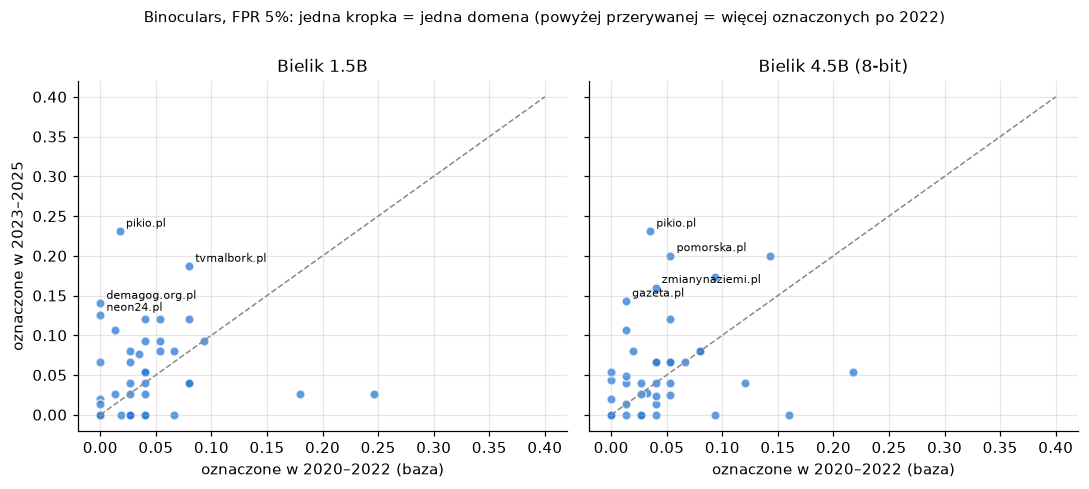

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
for ax, p in zip(axes, PRESETS, strict=True):
    t = domains[(p, "binoculars")].dropna(subset=["rate_2020_22", "rate_2023_25"])
    ax.plot([0, 0.4], [0, 0.4], color=GRAY, ls="--", lw=1)
    ax.scatter(
        t["rate_2020_22"],
        t["rate_2023_25"],
        s=36,
        color=BLUE,
        alpha=0.75,
        edgecolor="white",
        linewidth=1,
    )
    for domain, row in t.nlargest(4, "excess").iterrows():
        ax.annotate(
            domain,
            (row["rate_2020_22"], row["rate_2023_25"]),
            fontsize=7,
            xytext=(4, 3),
            textcoords="offset points",
        )
    ax.set_title(PRESETS[p])
    ax.set_xlabel("oznaczone w 2020–2022 (baza)")
axes[0].set_ylabel("oznaczone w 2023–2025")
fig.suptitle(
    "Binoculars, FPR 5%: jedna kropka = jedna domena (powyżej przerywanej = więcej oznaczonych po 2022)",
    y=1.0,
    fontsize=10,
)
fig.tight_layout()
plt.show()

In [13]:
top = pd.concat(
    [
        domains[(p, "binoculars")]
        .nsmallest(8, "p_value")
        .assign(model=PRESETS[p])
        .reset_index()
        for p in PRESETS
    ]
)
display(
    top[
        [
            "model",
            "domain",
            "stratum",
            "n_2020_22",
            "rate_2020_22",
            "n_2023_25",
            "rate_2023_25",
            "p_value",
            "q_value",
        ]
    ]
    .set_index(["model", "domain"])
    .style.format(
        {
            "rate_2020_22": pct,
            "rate_2023_25": pct,
            "p_value": "{:.3f}".format,
            "q_value": "{:.2f}".format,
        }
    )
)

Jak to czytać: domena jest przekonującym kandydatem, jeśli (a) ma wysoki `rate_2023_25` przy niskim `rate_2020_22`, (b) ma małe q-value i (c) pojawia się **w obu modelach i w kilku detektorach**.
Na jedną domenę przypada tu zaledwie 25–75 tekstów na okres, więc pojedyncze wyniki są bardzo niepewne.

## 7. Zgodność detektorów i modeli

Jeśli detektory naprawdę wykrywają to samo zjawisko, powinny wskazywać te same teksty i te same domeny.
Niska zgodność znaczy, że w dużej części to szum.

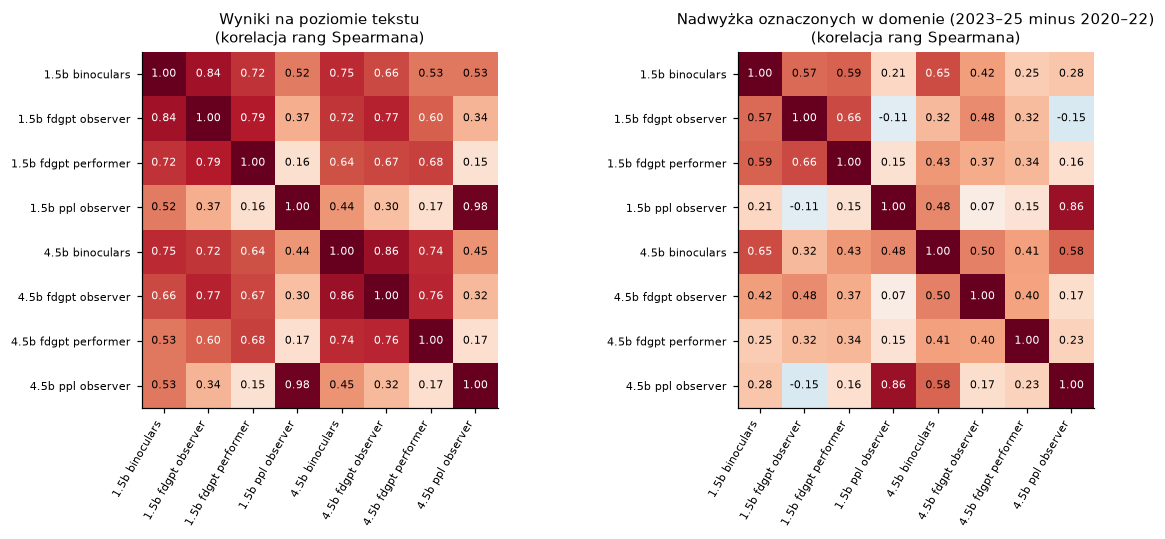

In [ ]:
def short(p: str, det: str) -> str:
    if det == PANGRAM:
        return "Pangram"
    return f"{p.removeprefix('bielik-')} {det.replace('fastdetectgpt_', 'fdgpt ').replace('logppl_', 'ppl ')}"


def heatmap(ax, matrix: pd.DataFrame, title: str) -> None:
    im = ax.imshow(matrix.to_numpy(), vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(
        range(len(matrix)), matrix.columns, rotation=60, ha="right", fontsize=7
    )
    ax.set_yticks(range(len(matrix)), matrix.index, fontsize=7)
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            value = matrix.iat[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=7,
                color="white" if abs(value) > 0.6 else "black",
            )
    ax.grid(False)
    ax.set_title(title, fontsize=10)
    return im


# Indeks to article_id, bo Pangram może mieć wynik dla innego zbioru artykułów
text_scores = pd.DataFrame(
    {
        short(p, det): pd.Series(
            machine_score(data[p], det).to_numpy(),
            index=data[p]["article_id"].to_numpy(),
        )
        for p in PANELS
        for det in PANEL_DETECTORS[p]
    }
)
domain_excess = pd.DataFrame(
    {
        short(p, det): domains[(p, det)]["excess"]
        for p in PANELS
        for det in PANEL_DETECTORS[p]
    }
)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
heatmap(
    axes[0],
    text_scores.corr(method="spearman"),
    "Wyniki na poziomie tekstu\n(korelacja rang Spearmana)",
)
heatmap(
    axes[1],
    domain_excess.corr(method="spearman"),
    "Nadwyżka oznaczonych w domenie (2023–25 minus 2020–22)\n(korelacja rang Spearmana)",
)
fig.tight_layout()
plt.show()


- **Na poziomie tekstu** Binoculars i oba warianty Fast-DetectGPT są silnie skorelowane (0,6–0,9), czyli mierzą podobne zjawisko, i to niezależnie od rozmiaru modelu.
- **Zwykła perplexity** (`ppl observer`) zachowuje się inaczej: koreluje z resztą słabo (0,2–0,5), a między modelem 1.5B i 4.5B niemal idealnie (0,98).
  To znaczy, że głównie mierzy „trudność” samego tekstu (temat, słownictwo), a nie to, czy napisała go maszyna. Dlatego traktujemy ją tylko jako punkt odniesienia.
- **Na poziomie domen** zgodność jest wyraźnie niższa (dla Binoculars między modelami około 0,65, dla pozostałych par często poniżej 0,4).
  To sygnał ostrzegawczy: przy kilkudziesięciu tekstach na okres różnice między domenami to w dużej części szum losowania.

In [15]:
# Czy te same teksty z lat 2023-2025 są oznaczane przez oba modele? (Binoculars, FPR 5%)
a = flags[(SMALL, "binoculars", MAIN_FPR)]
b = flags[(LARGE, "binoculars", MAIN_FPR)]
after = ~data[SMALL]["human"]
rows = []
for label, mask in (("2020–2022", ~after), ("2023–2025", after)):
    n = int(mask.sum())
    both, only_s, only_l = (
        int((a & b & mask).sum()),
        int((a & ~b & mask).sum()),
        int((~a & b & mask).sum()),
    )
    expected = a[mask].mean() * b[mask].mean() * n
    rows.append(
        {
            "okres": label,
            "n": n,
            "oba modele": both,
            "tylko 1.5B": only_s,
            "tylko 4.5B": only_l,
            "oba modele przy niezależności": round(expected, 1),
        }
    )
display(pd.DataFrame(rows).set_index("okres"))

,n,oba modele,tylko 1.5B,tylko 4.5B,oba modele przy niezależności
okres,,,,,
2020–2022,2847,69,72,69,6.8
2023–2025,2179,66,61,58,7.2


## 8. Moc testu i korekta na czułość

To najważniejsza sekcja do interpretacji wyniku.

**Problem.** Detektor wykrywa tylko część tekstów AI (czułość, TPR; na Śmigielu przy FPR 5% to około połowa).
Jeśli w domenie 20% tekstów to AI, a detektor widzi połowę z nich, to odsetek oznaczonych wzrośnie tylko o ok. 10 punktów procentowych, a przy 75 tekstach na okres to trudno odróżnić od losowości.

**8a. Szacunek udziału AI.** Jeśli odsetek oznaczonych w danej grupie to `r`, bazowy odsetek fałszywych alarmów to `b` (z lat 2020–2022), a czułość to `TPR`, to udział AI w grupie wynosi w przybliżeniu

`udział AI ≈ (r − b) / (TPR − b)`.

Czułości nie znamy dla naszych artykułów (Śmigiel ma inny charakter niż polskie newsy i inne generatory niż te, których używają serwisy), więc **pokazujemy wynik dla całego przedziału możliwych TPR**.
Wartość ujemna lub bliska zeru oznacza: brak nadwyżki ponad poziom bazowy.

In [16]:
tprs = [0.2, 0.35, 0.5, 0.7, 0.9]
rows = []
for p in PRESETS:
    c = compare_periods(p, "binoculars", MAIN_FPR)
    b, r, n1 = c["odsetek 2020–22"], c["odsetek 2023–25"], c["n 2023–25"]
    lo, hi = wilson_interval(c["oznaczone 2023–25"], n1)
    tpr_smigiel_p = tpr_smigiel[(p, "binoculars", MAIN_FPR)]
    for t in tprs + [tpr_smigiel_p]:
        rows.append(
            {
                "model": PRESETS[p],
                "założona czułość (TPR)": f"{t:.2f}"
                + (" (ze Śmigiela)" if t == tpr_smigiel_p else ""),
                "szacowany udział AI w 2023–25": (r - b) / (t - b),
                "95% CI (tylko niepewność r)": f"[{pct((lo - b) / (t - b))}; {pct((hi - b) / (t - b))}]",
            }
        )
prevalence = pd.DataFrame(rows)
display(
    prevalence.set_index(["model", "założona czułość (TPR)"]).style.format(
        {"szacowany udział AI w 2023–25": pct}
    )
)

**8b. Jak duże zjawisko jesteśmy w stanie zobaczyć w pojedynczej domenie?**
Symulacja: domena ma 75 tekstów z lat 2020–2022 i 75 z lat 2023–2025 (typowa liczebność w naszych danych).
Zakładamy, że w 2023–2025 pewien udział tekstów to AI wykrywane z czułością TPR ze Śmigiela, a pozostałe są oznaczane na poziomie FPR.
Pokazujemy, jak często test Fishera (p<0,05) wykryłby taką domenę (moc testu).

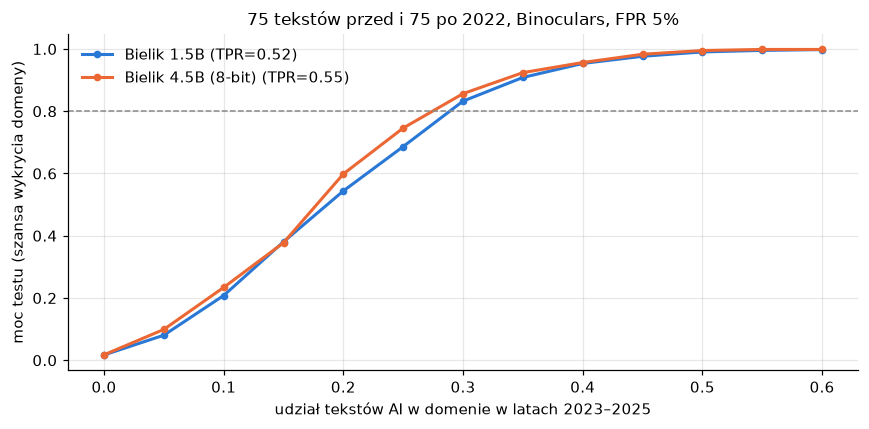

Najmniejszy udział AI wykrywany z mocą >= 80%: {'Bielik 1.5B': '30.0%', 'Bielik 4.5B (8-bit)': '30.0%'}


In [17]:
rng = np.random.default_rng(42)
shares = np.arange(0, 0.65, 0.05)
REPS = 2000


def power(n0: int, n1: int, base: float, tpr: float, share: float) -> float:
    k0 = rng.binomial(n0, base, REPS)
    k1 = rng.binomial(n1, base * (1 - share) + tpr * share, REPS)
    return float(
        np.mean(
            [
                fisher(int(x1), n1, int(x0), n0) < 0.05
                for x1, x0 in zip(k1, k0, strict=True)
            ]
        )
    )


fig, ax = plt.subplots(figsize=(8, 4))
needed = {}
for p, color in zip(PRESETS, [BLUE, ORANGE], strict=True):
    tpr = tpr_smigiel[(p, "binoculars", MAIN_FPR)]
    curve = [power(75, 75, MAIN_FPR, tpr, s) for s in shares]
    ax.plot(
        shares,
        curve,
        color=color,
        marker="o",
        ms=4,
        lw=2,
        label=f"{PRESETS[p]} (TPR={tpr:.2f})",
    )
    reached = [s for s, c in zip(shares, curve, strict=True) if c >= 0.8]
    needed[PRESETS[p]] = reached[0] if reached else None
ax.axhline(0.8, color=GRAY, ls="--", lw=1)
ax.set_xlabel("udział tekstów AI w domenie w latach 2023–2025")
ax.set_ylabel("moc testu (szansa wykrycia domeny)")
ax.set_title("75 tekstów przed i 75 po 2022, Binoculars, FPR 5%")
ax.legend()
fig.tight_layout()
plt.show()
print(
    "Najmniejszy udział AI wykrywany z mocą >= 80%:",
    {k: (pct(v) if v is not None else "poza zakresem") for k, v in needed.items()},
)

Interpretacja: domena, w której AI to mniej niż wskazany udział, **pozostanie niewidoczna** nawet jeśli detektor działa dobrze.
Brak istotnej domeny nie dowodzi więc, że nikt nie używa AI — dowodzi tylko, że nie ma domen, w których AI stanowi dużą część tekstów (w zakresie czułości detektora na takim materiale).

## 9. Kandydaci do ręcznego przeglądu

Teksty z lat 2023–2025, które **oba modele** oznaczyły metodą Binoculars przy FPR 5%.
To nie jest lista „artykułów z AI”: przy FPR 5% część z nich to fałszywe alarmy.
Lista służy do (a) ręcznego przejrzenia kilkunastu tekstów, (b) wysłania do drugiego niezależnego detektora (np. Pangram API), (c) porównania z losowymi tekstami z lat 2020–2022.

Plik `data/detect/candidates.csv` zawiera tylko adresy URL, metadane i wyniki (bez treści artykułów).

In [18]:
mask = (
    (~data[SMALL]["human"])
    & flags[(SMALL, "binoculars", MAIN_FPR)]
    & flags[(LARGE, "binoculars", MAIN_FPR)]
)
candidates = pd.DataFrame(
    {
        "domain": data[SMALL]["domain"],
        "stratum": data[SMALL]["stratum"],
        "pub_year": data[SMALL]["pub_year"],
        "url": data[SMALL]["url"],
        "title": data[SMALL]["title"],
        "binoculars_1.5b": data[SMALL]["binoculars"],
        "binoculars_4.5b": data[LARGE]["binoculars"],
        "fdgpt_obs_1.5b": data[SMALL]["fastdetectgpt_observer"],
        "fdgpt_obs_4.5b": data[LARGE]["fastdetectgpt_observer"],
    }
)[mask]
candidates["mean_binoculars"] = candidates[["binoculars_1.5b", "binoculars_4.5b"]].mean(
    axis=1
)
candidates = candidates.sort_values("mean_binoculars").reset_index(drop=True)
candidates.to_csv(DETECT_DIR / "candidates.csv", index=False)

a, b = flags[(SMALL, "binoculars", MAIN_FPR)], flags[(LARGE, "binoculars", MAIN_FPR)]
later = ~data[SMALL]["human"]
base_both = (a & b & ~later).sum() / (~later).sum()
print(f"{len(candidates)} kandydatów z {int(later.sum())} tekstów z lat 2023–2025")
print(
    f"Dla porównania: w latach 2020–2022 oba modele oznaczają {pct(base_both)} tekstów, "
    f"więc przy tym samym poziomie spodziewamy się ok. {base_both * later.sum():.0f} fałszywych alarmów "
    f"wśród tych {len(candidates)} kandydatów."
)
display(
    candidates.head(15)[
        ["domain", "pub_year", "title", "mean_binoculars", "url"]
    ].style.format({"mean_binoculars": "{:.3f}".format})
)
display(
    candidates.groupby("domain")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("liczba kandydatów")
    .to_frame()
)

66 kandydatów z 2179 tekstów z lat 2023–2025
Dla porównania: w latach 2020–2022 oba modele oznaczają 2.4% tekstów, więc przy tym samym poziomie spodziewamy się ok. 53 fałszywych alarmów wśród tych 66 kandydatów.


,domain,pub_year,title,mean_binoculars,url
0,niezalezna.pl,2024,Masło Ghee. Wszechstronny i zdrowy skarb w kuchni | Niezalezna.pl,0.745,https://niezalezna.pl/lifestyle/zdrowie-i-dom/maslo-ghee-wszechstronny-i-zdrowy-skarb-w-kuchni/523961
1,rmf24.pl,2025,Zagłębie Lubin w żałobie. Nie żyje kibic,0.766,"https://www.rmf24.pl/regiony/wroclaw/news-zaglebie-lubin-w-zalobie-nie-zyje-kibic,nId,8010807"
2,polsatnews.pl,2023,"Oscary 2023. Ogłoszono nominacje. Polski kandydat ""IO"" wyróżniony",0.768,https://www.polsatnews.pl/wiadomosc/2023-01-24/oscary-2023-ogloszono-nominacje-polski-kandydat-wyrozniony/
3,rmf24.pl,2024,Miód manuka. Jak działa? Ile kosztuje?,0.779,"https://twojezdrowie.rmf24.pl/choroby/odpornosc/news-miod-manuka-jak-dziala-ile-kosztuje,nId,7267311"
4,niezalezna.pl,2024,Nie lubię poniedziałku! Zobacz najlepsze MEMY o tym wyjątkowym dniu | Niezalezna.pl,0.791,https://niezalezna.pl/lifestyle/nie-lubie-poniedzialku-zobacz-najlepsze-memy-o-tym-wyjatkowym-dniu/532455
5,fakt.pl,2025,Trudne warunki na szlakach w Beskidach. Turyści powinni uważać,0.799,https://www.fakt.pl/wydarzenia/polska/gopr-ostrzega-przed-trudnymi-warunkami-w-beskidach-zagrozenie-lawinowe/vdh3vld
6,pomorska.pl,2023,Ponad 19 tys. zgłoszeń do udziału w kolejnej edycji akcji „Szkoła do hymnu”. Uroczyste odśpiewanie w całej Polsce o symbolicznej godzinie,0.802,https://pomorska.pl/ponad-19-tys-zgloszen-do-udzialu-w-kolejnej-edycji-akcji-szkola-do-hymnu-uroczyste-odspiewanie-w-calej-polsce-o-symbolicznej/ar/c5-18057999
7,onet.pl,2025,Wzruszające filmowe klasyki PRL. Dasz radę odpowiedzieć na wszystkie pytania?,0.810,https://kobieta.onet.pl/quizy/wyciskacze-lez-z-prl-pamietasz-jeszcze-te-kultowe-filmy/257fnff
8,o2.pl,2024,Oto emerytury zakonnic w Polsce. Gotowi? Sami spójrzcie na kwoty,0.811,https://www.o2.pl/biznes/oto-emerytury-zakonnic-w-polsce-gotowi-sami-spojrzcie-na-kwoty-7025294444862432a
9,tvmalbork.pl,2023,Malbork. Okradł placówkę opiekuńczo-wychowawczą dla dzieci. Włamywacz i paser w rękach policji. | TvMalbork.pl,0.813,"https://tvmalbork.pl/aktualnosci/41182,malbork-okradl-placowke-opiekunczo-wychowawcza-dla"


,liczba kandydatów
domain,
tvmalbork.pl,9
wp.pl,5
tvn24.pl,5
zmianynaziemi.pl,4
rmf24.pl,4
neon24.pl,4
epoznan.pl,3
pomorska.pl,3
polsatnews.pl,3


## 10. Wnioski i następne kroki

*Stan na wyniki z `data/detect/` (5026 artykułów, 44 domeny). Po zmianie danych lub ustawień należy ponownie uruchomić notebook i zaktualizować liczby w tej sekcji. Poniższe wnioski dotyczą detektorów Bielika; wnioski o Pangramie trzeba dopisać po pełnym przebiegu i uruchomieniu notebooka z jego wynikami.*

### Co ustaliliśmy

1. **Implementacja działa i jest zgodna z literaturą.** Binoculars na próbce Śmigiela daje trafność 0,77–0,79 (AUC 0,83–0,85), a w PolEval 2025 zwycięskie zgłoszenie z tą metodą miało około 0,80. Binoculars jest najlepszym z czterech detektorów, a zwykła perplexity najgorszym.
2. **Większy model nie pomaga wyraźnie.** Para 4.5B (8-bit) ma AUC 0,85 wobec 0,83 dla 1.5B, a przy FPR 1% czułość nawet niższą (0,27 wobec 0,35). Wniosek: do tego zadania wystarczy mały model, a dwa modele traktujemy jako wzajemną kontrolę, nie jako „słabszy i mocniejszy”.
3. **Próg przenosi się na nowe dane.** Na odłożonym zbiorze `test` (lata 2020–2022) odsetek fałszywych alarmów wynosi 3,8–6,9% przy docelowych 5%, a w kolejnych latach 2020–2022 odsetek oznaczonych jest płaski (test placebo przechodzi).
4. **Nie widać istotnej nadwyżki oznaczonych tekstów po 2022 r.** Dla Binoculars przy FPR 5%: 5,0% → 5,8% (1.5B, p≈0,10) i 4,8% → 5,7% (4.5B, p≈0,10). Pozostałe detektory różnią się o 1 punkt procentowy lub mniej (p>0,2). Dla Binoculars różnica jest dodatnia w warstwach S1 i S2 w obu modelach (od +0,4 do +1,2 pp), ale nigdzie nie jest istotna. Przy FPR 1% najbliżej istotności jest model 4.5B (+0,5 pp, p=0,06–0,08 dla Binoculars i Fast-DetectGPT), ale model 1.5B tego nie potwierdza (od −0,5 do 0,0 pp), więc nie traktujemy tego jako wyniku.
5. **Jeśli efekt jest realny, jest niewielki.** Przy czułości 0,5 szacowany udział tekstów AI w latach 2023–2025 to około 2% (95% CI do około 4%). Przy pesymistycznej czułości 0,2 górna granica rośnie do około 13%. Ten rząd wielkości zależy od czułości, której na naszych danych **nie znamy**.
6. **Na poziomie domen nie ma mocnego sygnału.** Po poprawce na 44 testy istotna jest jedna domena w jednym modelu (`demagog.org.pl`, q=0,05) i żadna w drugim. Domen z p<0,05 jest 4–5 przy około 2 oczekiwanych z samego przypadku. Zgodność domen między modelami jest umiarkowana (korelacja 0,65). Powtarzają się w obu modelach m.in. `polsatnews.pl`, `pikio.pl` (tylko 13 tekstów z lat 2023–2025), `zmianynaziemi.pl` i `tvmalbork.pl`, ale to są **hipotezy do sprawdzenia, nie wyniki**. `tvmalbork.pl` ma przy tym wysoki poziom fałszywych alarmów już w 2020–2022 (8–9%), czyli ten detektor pracuje tam gorzej.
7. **Moc testu jest niska.** Przy 75 tekstach na okres pojedyncza domena jest wykrywana z mocą 80% dopiero wtedy, gdy AI stanowi około 30% jej tekstów z lat 2023–2025. Brak istotnych domen **nie wyklucza** serwisów z kilkunastoma procentami tekstów AI.
8. **Lista kandydatów jest głównie szumem.** 66 tekstów oznaczonych przez oba modele to nie dużo więcej niż spodziewane fałszywe alarmy (około 53 przy poziomie z lat 2020–2022). Do ręcznego przejrzenia, nie do wniosków.

### Ograniczenia, które trzeba opisać w raporcie

- **Czułość znamy tylko ze Śmigiela**, czyli dla krótkich fragmentów i generatorów open-source (Bielik, PLLuM, Llama, Mistral, Gemma). Serwisy publikujące masowo treści AI najpewniej używają ChatGPT, Gemini lub Claude. Możliwe, że wykrywamy je gorzej, niż pokazuje Śmigiel.
- **Teksty AI mogą być zmieszane z ludzkimi** (AI pisze szkic, człowiek poprawia) i wtedy detektory zero-shot widzą je słabo.
- **Detektor ocenia tylko pierwsze 512 tokenów** (64% tekstów jest dłuższych).
- **„Ludzkie” teksty z lat 2020–2022 to założenie.** Mogą w nich być teksty generowane wcześniejszymi technikami (szablony, automatyczne tłumaczenia).
- **Bielik mógł widzieć nasze artykuły podczas trenowania**, co obniża perplexity tekstów ludzkich. Test placebo i porównanie z latami 2020–2022 częściowo to kontrolują.
- **Próbka jest mała** (25–75 tekstów na domenę i okres), a progu nie da się ustawić osobno dla każdej domeny.

### Następne kroki (od najważniejszego)

1. **Zmierzyć czułość na własnych danych.** Dla kilkuset tytułów lub leadów z lat 2020–2022 wygenerować artykuły kilkoma modelami (Bielik i przynajmniej jeden komercyjny, np. ChatGPT lub Gemini), przepuścić przez te same detektory i obliczyć TPR przy FPR 5% i 1%. Bez tego nie wiemy, czy „brak sygnału” znaczy „brak AI”, czy „detektor jej nie widzi”. To najważniejszy brakujący element.
2. **Drugi, niezależny detektor.** Przepuścić przez Pangram (program badawczy: 200 000 kredytów, nasze 5026 tekstów to około 29 000) co najmniej 66 kandydatów i próbkę kontrolną z lat 2020–2022. Zgodność dwóch niezależnych metod będzie mocniejszym dowodem niż pojedyncze progi.
3. **Ręczny przegląd w ślepej próbie.** 30–50 kandydatów wymieszanych z 30–50 losowymi tekstami z lat 2020–2022; osoba oceniająca nie wie, które są które. Zapisać oceny w pliku, to da kolejną miarę wiarygodności.
4. **Dobrać więcej tekstów dla domen-kandydatów** (np. `pikio.pl` ma tylko 13 tekstów z lat 2023–2025), zwiększając kwotę w ustawieniach pobierania (`articles_per_domain_year`).
5. **Opisać wynik jako przedział, nie jako liczbę „farm”.** Sformułowanie „w próbce nie wykryto nadwyżki ponad poziom bazowy; górna granica udziału AI wynosi ok. X% przy założonej czułości Y” jest uczciwsze niż lista domen.
6. **Jeśli punkt 1 pokaże niską czułość**, rozważyć detektor trenowany nadzorowanie (np. Qwen3, XLM-R lub mDeBERTa) na Śmigielu i własnych syntetycznych newsach. W literaturze (CEAID, PolEval) takie modele są wyraźnie dokładniejsze w znanej domenie, ale gorzej uogólniają na nowe generatory, więc wymagałyby tej samej kontroli.
